# Calibrating GRAVITY products

The GRAVITY pipeline gives you *uncalibrated* visibilities: every V² is the target's true V² times the instrument's **transfer function**, which changes with wavelength and drifts during the night. Calibrator stars, unresolved or of known size, are observed between the science exposures to measure it.

`virgil-vlti-calibrate` does the rest, night by night:

1. it measures the transfer function on every calibrator exposure, per baseline and channel;
2. it interpolates it in time to each science frame and divides it out of V²; it also subtracts the calibrators' closure phases (averaged as unit vectors);
3. it adds the interpolation's own uncertainty to the errors;
4. it writes calibrated OIFITS files that virgil reads directly.

In this tutorial we simulate one night of GRAVITY data with a known truth, calibrate it, and check the result against the truth.

In [1]:
import csv
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from virgil.plotting import set_style

from virgil_vlti import read_exposure
from virgil_vlti.cli import main as calibrate
from virgil_vlti.synthetic import write_product

set_style()  # the figure style of virgil's docs
rng = np.random.default_rng(1)
work = Path(tempfile.mkdtemp())
raw = work / "reduced"
raw.mkdir()

## A night at the VLTI

`virgil_vlti.synthetic.write_product` writes a product in the GRAVITY layout, with four telescopes, three frames five minutes apart, and V² and closure phases given by functions of the baseline, wavelength and time.

The **instrument** multiplies V² by a transfer function that is chromatic and drifts by 10% over the night, and adds a chromatic closure phase of a few degrees. The **science target** is a Gaussian disk 2.5 mas across (FWHM); the calibrators are point sources. Both get Gaussian noise of the size of their reported errors.

In [2]:
WAVE = np.linspace(2.0e-6, 2.4e-6, 40)  # 40 K-band channels
T0 = 60400.1  # MJD of the first exposure
MAS = np.pi / 180 / 3600 / 1000
FWHM = 2.5  # mas
SIGMA_V2, SIGMA_CP = 0.01, 0.5  # reported errors (V², degrees)


def transfer(t, wave):
    """The V² transfer function: chromatic, and drifting during the night."""
    return (0.85 - 0.6 * (t - T0)) * (wave / 2.2e-6) ** 0.5


def instrumental_cp(wave):
    """The instrument's closure phase, in degrees."""
    return 3.0 + 4.0 * (wave - 2.2e-6) / 0.2e-6


def disk_v2(u, v, wave):
    """The science target: a Gaussian disk."""
    rho = np.hypot(u, v) / wave
    return np.exp(-((np.pi * FWHM * MAS * rho) ** 2) / (2 * np.log(2)))


def observe(name, t, star):
    true_v2 = (lambda u, v, w: np.ones_like(w)) if star else disk_v2
    return write_product(
        raw / f"{name}.fits",
        mjd=t,
        wave=WAVE,
        vis2=lambda u, v, w, tk: (
            true_v2(u, v, w) * transfer(tk, w) + rng.normal(0, SIGMA_V2, w.size)
        ),
        t3phi=lambda u1, v1, u2, v2, w, tk: instrumental_cp(w) + rng.normal(0, SIGMA_CP, w.size),
        vis2err=SIGMA_V2,
        t3phierr=SIGMA_CP,
        catg="SINGLE_CAL_VIS" if star else "SINGLE_SCI_VIS",
        target="HD 1234" if star else "TARGET",
    )


# Calibrator, science, calibrator, ...: about an hour apart.
schedule = [
    ("cal1", 0.00, True),
    ("sci1", 0.04, False),
    ("cal2", 0.08, True),
    ("sci2", 0.12, False),
    ("cal3", 0.16, True),
]
for name, dt, star in schedule:
    observe(name, T0 + dt, star)
print(sorted(p.name for p in raw.iterdir()))

['cal1.fits', 'cal2.fits', 'cal3.fits', 'sci1.fits', 'sci2.fits']


The raw V² of one baseline at 2.2 µm shows the problem. The calibrators (blue) trace the drifting transfer function. The science target (red) sits below it, because it is resolved, but its V² is the product of both.

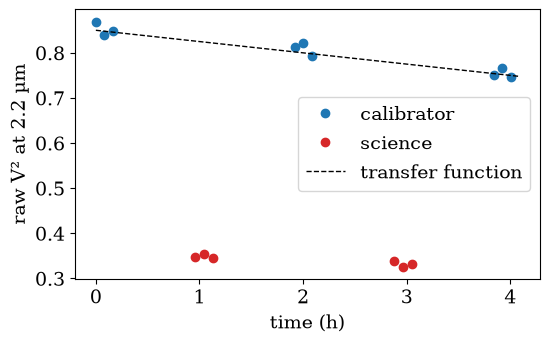

In [3]:
INS = "GRAVITY_SC"
mid = np.argmin(np.abs(WAVE - 2.2e-6))

fig, ax = plt.subplots(figsize=(6, 3.5))
for name, _, star in schedule:
    d = read_exposure(str(raw / f"{name}.fits")).v2[INS].data
    first = d["STA_INDEX"][0]
    rows = (d["STA_INDEX"] == first).all(axis=1)  # one baseline
    ax.plot(
        (d["MJD"][rows] - T0) * 24,
        d["VIS2DATA"][rows, mid],
        "o",
        color="C0" if star else "C3",
        label=("calibrator" if star else "science") if name in ("cal1", "sci1") else None,
    )
hours = np.linspace(0, 0.17, 50)
ax.plot(hours * 24, transfer(T0 + hours, 2.2e-6), "k--", lw=1, label="transfer function")
ax.set(xlabel="time (h)", ylabel="raw V² at 2.2 µm")
ax.legend()
plt.show()

## Calibrating

From the command line this is

```bash
virgil-vlti-calibrate reduced/ --out calibrated
```

Here we call the same entry point from Python. With no options, the product category in each header (`SINGLE_CAL_VIS` or `SINGLE_SCI_VIS`) says which exposures are calibrators. With GRAVITY in dual field, `--dual-field` uses the fringe-tracking star as an in-field calibrator instead. With named calibrator stars, `--cal "HD 1234=0.45±0.03"` gives each one's uniform-disk diameter (mas) and its error.

In [4]:
out = work / "calibrated"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    calibrate([str(raw), "--out", str(out)])

with open(out / "index.csv") as f:
    for row in csv.DictReader(f):
        print(row["source"], "->", row["calibrated"], "  good V²:", row["good_v2_fraction"])

2024-03-31T03:21:36  3 CAL  -> 2024-03-30/target_20240331T032136.fits  (good V2 1.00)
2024-03-31T05:16:48  3 CAL  -> 2024-03-30/target_20240331T051648.fits  (good V2 1.00)
sci1.fits -> 2024-03-30/target_20240331T032136.fits   good V²: 1.0
sci2.fits -> 2024-03-30/target_20240331T051648.fits   good V²: 1.0


One calibrated OIFITS file per science exposure, and an `index.csv` listing them.

## Checking against the truth

virgil reads the calibrated files directly. We compare them with the true Gaussian disk, through virgil's own model.

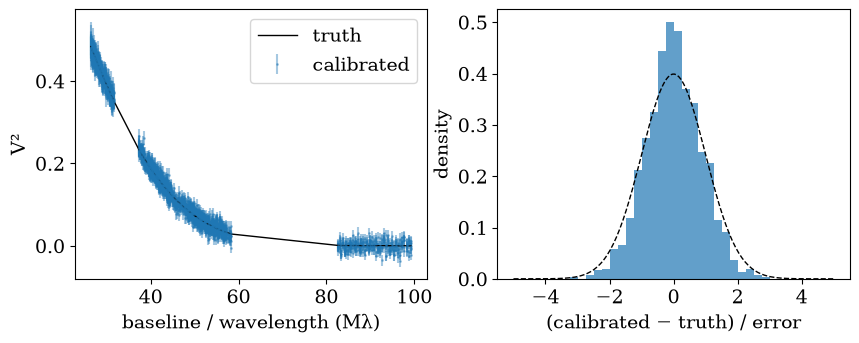

V² pulls: mean -0.01, rms 0.87
closure phases: mean -0.02°, rms 0.53° (reported error 0.5°)


In [5]:
from virgil.models import GaussianDisk
from virgil.oidata import OIData
from virgil.oifits import read_oifits

files = sorted(str(p) for p in out.glob("*/*.fits"))
data = OIData(read_oifits(files, insname=INS))
truth = GaussianDisk(sigma=FWHM / (2 * np.sqrt(2 * np.log(2))))

n_vis = data.vis.size
model = np.asarray(data.model(truth))
vis, err = np.asarray(data.vis), np.asarray(data.d_vis)
samples = np.arange(data.u.size) if data.vis_index is None else np.asarray(data.vis_index)
wavel = np.broadcast_to(np.asarray(data.wavel), np.shape(data.u))
rho = np.hypot(data.u, data.v)[samples] / wavel[samples] / 1e6  # Mλ
pull = (vis - model[:n_vis]) / err

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.errorbar(rho, vis, err, fmt=".", ms=2, alpha=0.4, label="calibrated")
order = np.argsort(rho)
ax1.plot(rho[order], model[:n_vis][order], "k", lw=1, label="truth")
ax1.set(xlabel="baseline / wavelength (Mλ)", ylabel="V²")
ax1.legend()
bins = np.linspace(-5, 5, 41)
ax2.hist(pull, bins, density=True, alpha=0.7)
x = np.linspace(-5, 5, 200)
ax2.plot(x, np.exp(-(x**2) / 2) / np.sqrt(2 * np.pi), "k--", lw=1)
ax2.set(xlabel="(calibrated − truth) / error", ylabel="density")
plt.show()

cp = np.rad2deg(np.asarray(data.phi))
print(f"V² pulls: mean {pull.mean():+.2f}, rms {pull.std():.2f}")
print(f"closure phases: mean {cp.mean():+.2f}°, rms {cp.std():.2f}° (reported error {SIGMA_CP}°)")

The transfer function and the instrumental closure phase are gone. The calibrated V² follow the truth, and their errors, which include the transfer function's interpolation error (a leave-one-out prediction error by default, `--tf-error loo`), describe the scatter.

## What the errors leave out

The added transfer-function error is treated as **independent between channels**. Real calibration errors are not: a frame's gain on a baseline is shared by all its channels, which is why diagonal errors make spectro-interferometric data look far more precise than they are. The next two tutorials measure that structure, with [the pair test](pair_test.md) and with [calibration templates](templates.md), and hand it to virgil, which marginalises it (`OIData.with_gains`).

Useful options (all are listed by `virgil-vlti-calibrate --help`):

| Option | What it does |
|---|---|
| `--dual-field` | the fringe-tracking star as in-field calibrator (GRAVITY) |
| `--cal NAME[=DIAM±ERR]` | name the calibrators, with uniform-disk diameters (mas) |
| `--window LO HI`, `--bin N` | keep a channel window (µm) and bin channels |
| `--interp linear\|gaussian` | interpolation in time (linear, or the pipeline's Gaussian weights) |
| `--tf-error loo\|scatter\|propagated` | the transfer function's error: leave-one-out (default), the night's scatter, or statistical only (with `--template`) |
| `--tf-modes` | that error as nuisance modes, one per night and baseline or triangle, instead of independent errors ([details](command_line.md)) |
| `--tf-mode-shape flat\|poly1\|poly2\|raw` | with `--tf-modes`, how each mode's channel shape is smoothed (default `poly1`, a polynomial in wavelength; `flat` is the channel mean, calibrated only for achromatic errors: pull rms 3.1 at colour 0.36 against about 1.3 for `poly1`, from our own Monte Carlo and not yet checked against ESO/VLTI documentation; `raw` is the noisy channel-by-channel estimate, for comparison only) |
| `--template NAME` | also write a calibration template's nuisance modes beside each file |
| `--match-gravity-viscal` | reproduce ESO's `gravity_viscal` exactly ([parity](instruments/gravity.md)) |